# I. Load data from .e

In [1]:
from read_fem import *

In [2]:
geo_model_name = "flat_ell"
if geo_model_name == "flat_ell":
    output_list_initd = [
        [
            'simulation_outputs/the11.e','simulation_outputs/the9.e','simulation_outputs/the13.e','simulation_outputs/the15.e'
        ],
        [
            r"No Prescribed Damage",
            r"Prescribed Damage at Depth $\approx 0.02\,$m",
            r"Prescribed Damage at Depth $\approx 0.05\,$m",
            r"Vertical Initial Cracks",
        ]
    ]
else:
    output_list_initd = [
        [
            'simulation_outputs/the12.e','simulation_outputs/the10.e','simulation_outputs/the14.e','simulation_outputs/the16.e'
        ],
        [
            r"No Prescribed Damage",
            r"Prescribed Damage at Depth $\approx 0.02\,$m",
            r"Prescribed Damage at Depth $\approx 0.05\,$m",
            r"Vertical Initial Cracks",
        ]
    ]
                
output_list=[output_list_initd[0],output_list_initd[1]]
node_variable_idx=[1, 2 ,3 ,4]
node_var_labels=[[r"Temperature $\theta\;(^{\circ}C)$", ""],
                 [r"Phase Field Fracture Damage", ""],
                 [r"Displacement $u_x$ (m)", ""],
                 [r"Displacement $u_y$ (m)", ""]]

element_variable_idx=[8,10,9,21]#12]
elt_var_labels=[[r"Stress $\sigma_{xx}$ MPa", ""],
                [r"Stress $\sigma_{yy}$ MPa",""],
                [r"Stress $\sigma_{xy}$ MPa", ""],
                [r"Thermal conductivity W/(m$\cdot^\circ$ C)", ""],
                ]
output_list


[['simulation_outputs/the11.e',
  'simulation_outputs/the9.e',
  'simulation_outputs/the13.e',
  'simulation_outputs/the15.e'],
 ['No Prescribed Damage',
  'Prescribed Damage at Depth $\\approx 0.02\\,$m',
  'Prescribed Damage at Depth $\\approx 0.05\\,$m',
  'Vertical Initial Cracks']]

In [3]:
profiles = [read_vars(e_name, node_variable_idx, element_variable_idx) for e_name in output_list[0]]
model_index=1
nodes, connect_components, global_connection, node_vars, elet_vars,times=profiles[model_index]

['time_whole', 'eb_status', 'eb_prop1', 'ns_status', 'ns_prop1', 'ss_status', 'ss_prop1', 'coordx', 'coordy', 'eb_names', 'ns_names', 'ss_names', 'coor_names', 'node_num_map', 'connect1', 'connect2', 'elem_num_map', 'elem_ss1', 'side_ss1', 'elem_ss2', 'side_ss2', 'elem_ss3', 'side_ss3', 'elem_ss4', 'side_ss4', 'elem_ss5', 'side_ss5', 'node_ns1', 'node_ns2', 'node_ns3', 'node_ns4', 'node_ns5', 'name_nod_var', 'vals_nod_var1', 'vals_nod_var2', 'vals_nod_var3', 'vals_nod_var4', 'name_elem_var', 'vals_elem_var1eb1', 'vals_elem_var2eb1', 'vals_elem_var3eb1', 'vals_elem_var4eb1', 'vals_elem_var5eb1', 'vals_elem_var6eb1', 'vals_elem_var7eb1', 'vals_elem_var8eb1', 'vals_elem_var9eb1', 'vals_elem_var10eb1', 'vals_elem_var11eb1', 'vals_elem_var12eb1', 'vals_elem_var13eb1', 'vals_elem_var14eb1', 'vals_elem_var15eb1', 'vals_elem_var16eb1', 'vals_elem_var17eb1', 'vals_elem_var18eb1', 'vals_elem_var19eb1', 'vals_elem_var20eb1', 'vals_elem_var21eb1', 'vals_elem_var22eb1', 'vals_elem_var23eb1', 'vals_

# Retrieve the scale of thermal conductivity

In [4]:
elet_vars[-1]/=1200

# Multiple plots in one plot

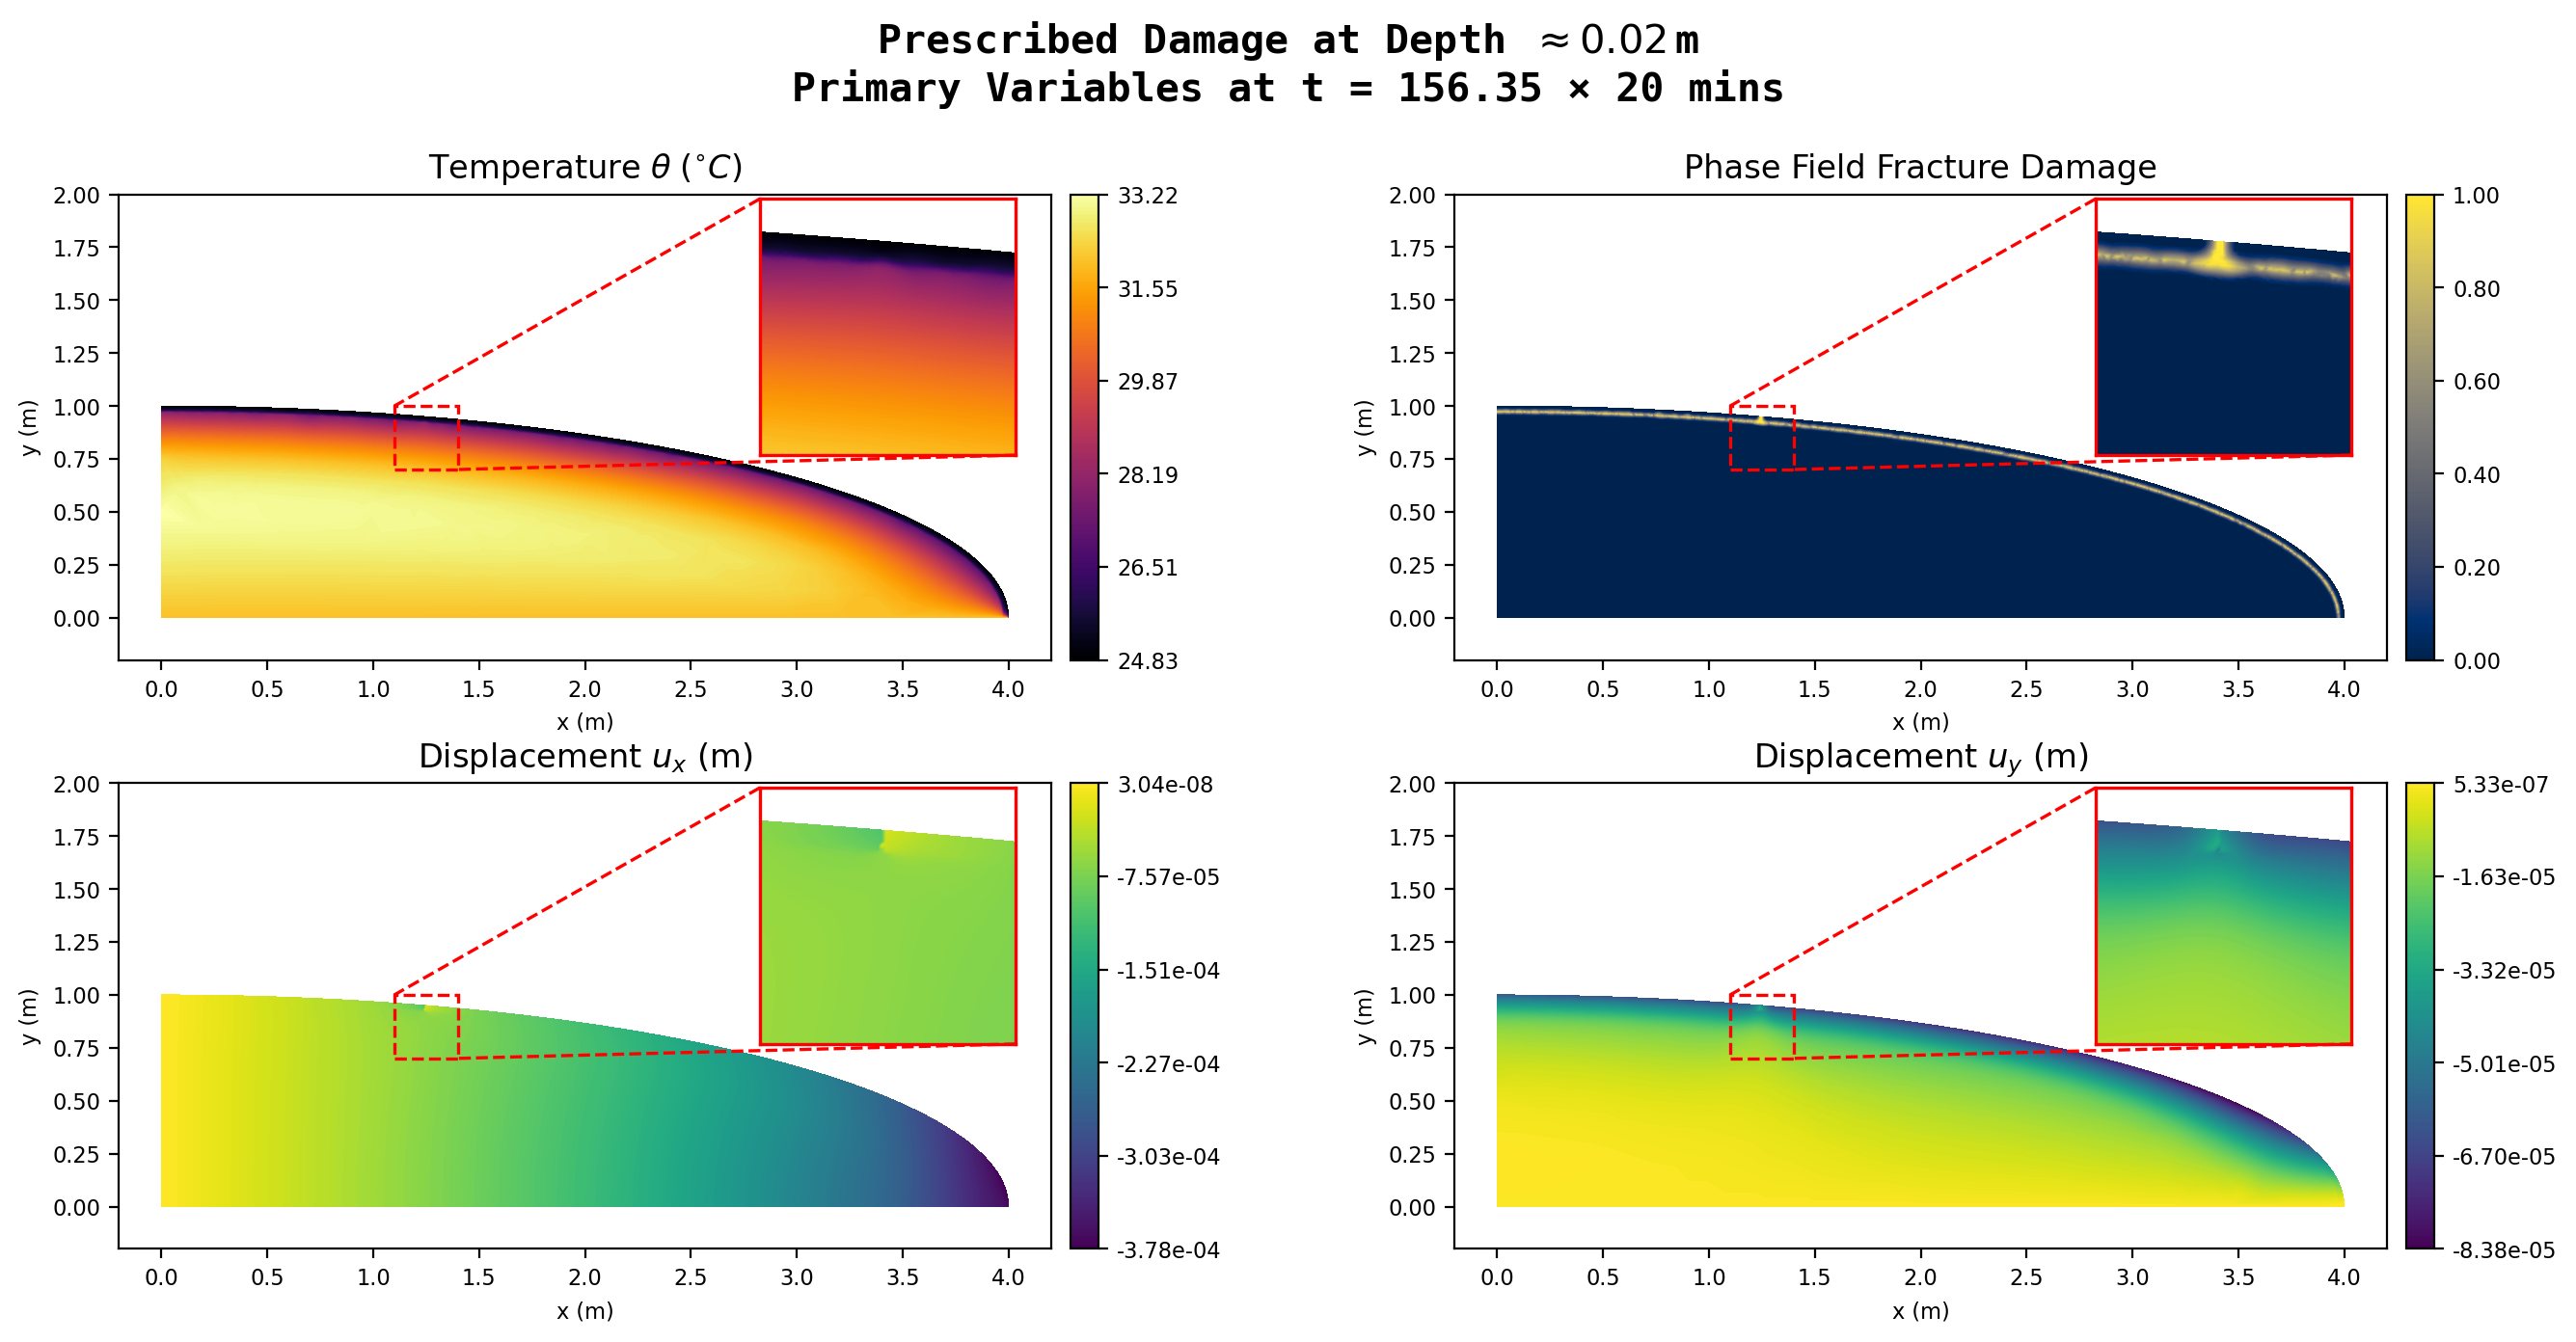

In [13]:
nr, nc = 2, 2  # 子圖數量設定
n_vars = len(node_vars)
step =  38  # 固定時間點
param_idx_list = range(n_vars)  # 要畫哪些變數（你也可以自訂 list）
color_maps=['inferno','cividis','viridis','viridis']
e_notations=[False,False,True,True]
zoom_color = ['red','red','red','red']
fig, axes = plt.subplots(nr, nc, figsize=(nc * 7, nr * 3.5), dpi=200)
if nr * nc == 1:
    axes = [axes]
else:
    axes = axes.flatten()

fig.suptitle(
    f"{output_list[1][model_index]}\nPrimary Variables at t = {times[step]:06.2f} × 20 mins",
    fontsize=15, fontweight="bold", fontname="DejaVu Sans Mono"
)


for i, idx in enumerate(param_idx_list):
    #vmin = node_vars[param_idx_list[i]].min()
    #vmax = node_vars[param_idx_list[i]].max()
    var = node_vars[idx][step]
    vmin = var.min()
    vmax = var.max()
    showNodePlot(
        nodes, global_connection, var,
        titlelabel=[node_var_labels[idx][0], node_var_labels[idx][1]],
        size=[6, 6], ax = axes[i], p_ext=[0.05, 0.5],
        colormap=color_maps[i], e_notation=e_notations[i],
        assign_bar_range=[vmin, vmax],
        x_unit=r'x (m)', y_unit=r'y (m)',
        font_adjust=1.35
    )

    x1, x2, y1, y2 = 1.1, 1.4, 0.7, 1  # subregion of the original image
    # 小圖（inset）

    axins = axes[i].inset_axes([0.55, 0.44, 0.55, 0.55])  # 位置固定
    showNodePlot(
        nodes, global_connection, var,
        titlelabel=["", ""],
        size=[0, 0], ax=axins, p_ext=[0, 0],  # ✅ 禁止擴張
        colormap=color_maps[i], e_notation=True,
        assign_bar_range=[vmin, vmax],
        x_unit="", y_unit="", font_adjust=0,show_cbar=False,levels_num=400
    )
    axins.set_xlim(x1, x2)
    axins.set_ylim(y1, y2)
    axins.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    for spine in axins.spines.values():
        spine.set_edgecolor(zoom_color[i])   # 顏色
        spine.set_linewidth(1.2)       # 線寬
        spine.set_linestyle("-")       # 線型（可選）

    mark_inset(axes[i], axins, loc1=2, loc2=4, fc="none", ec=zoom_color[i], lw=1.2, ls='--')
####################Add zoom on phase field only########################
    axes[i].set_ylim(-0.2,2)
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # 留空間給 suptitle
plt.show()
fig.savefig(f'figs/fig6b{geo_model_name}_primary_zoom_step{times[step]:.2f}.png')
fig.savefig(f'figs/fig6b{geo_model_name}_primary_step{times[step]:.2f}.svg')

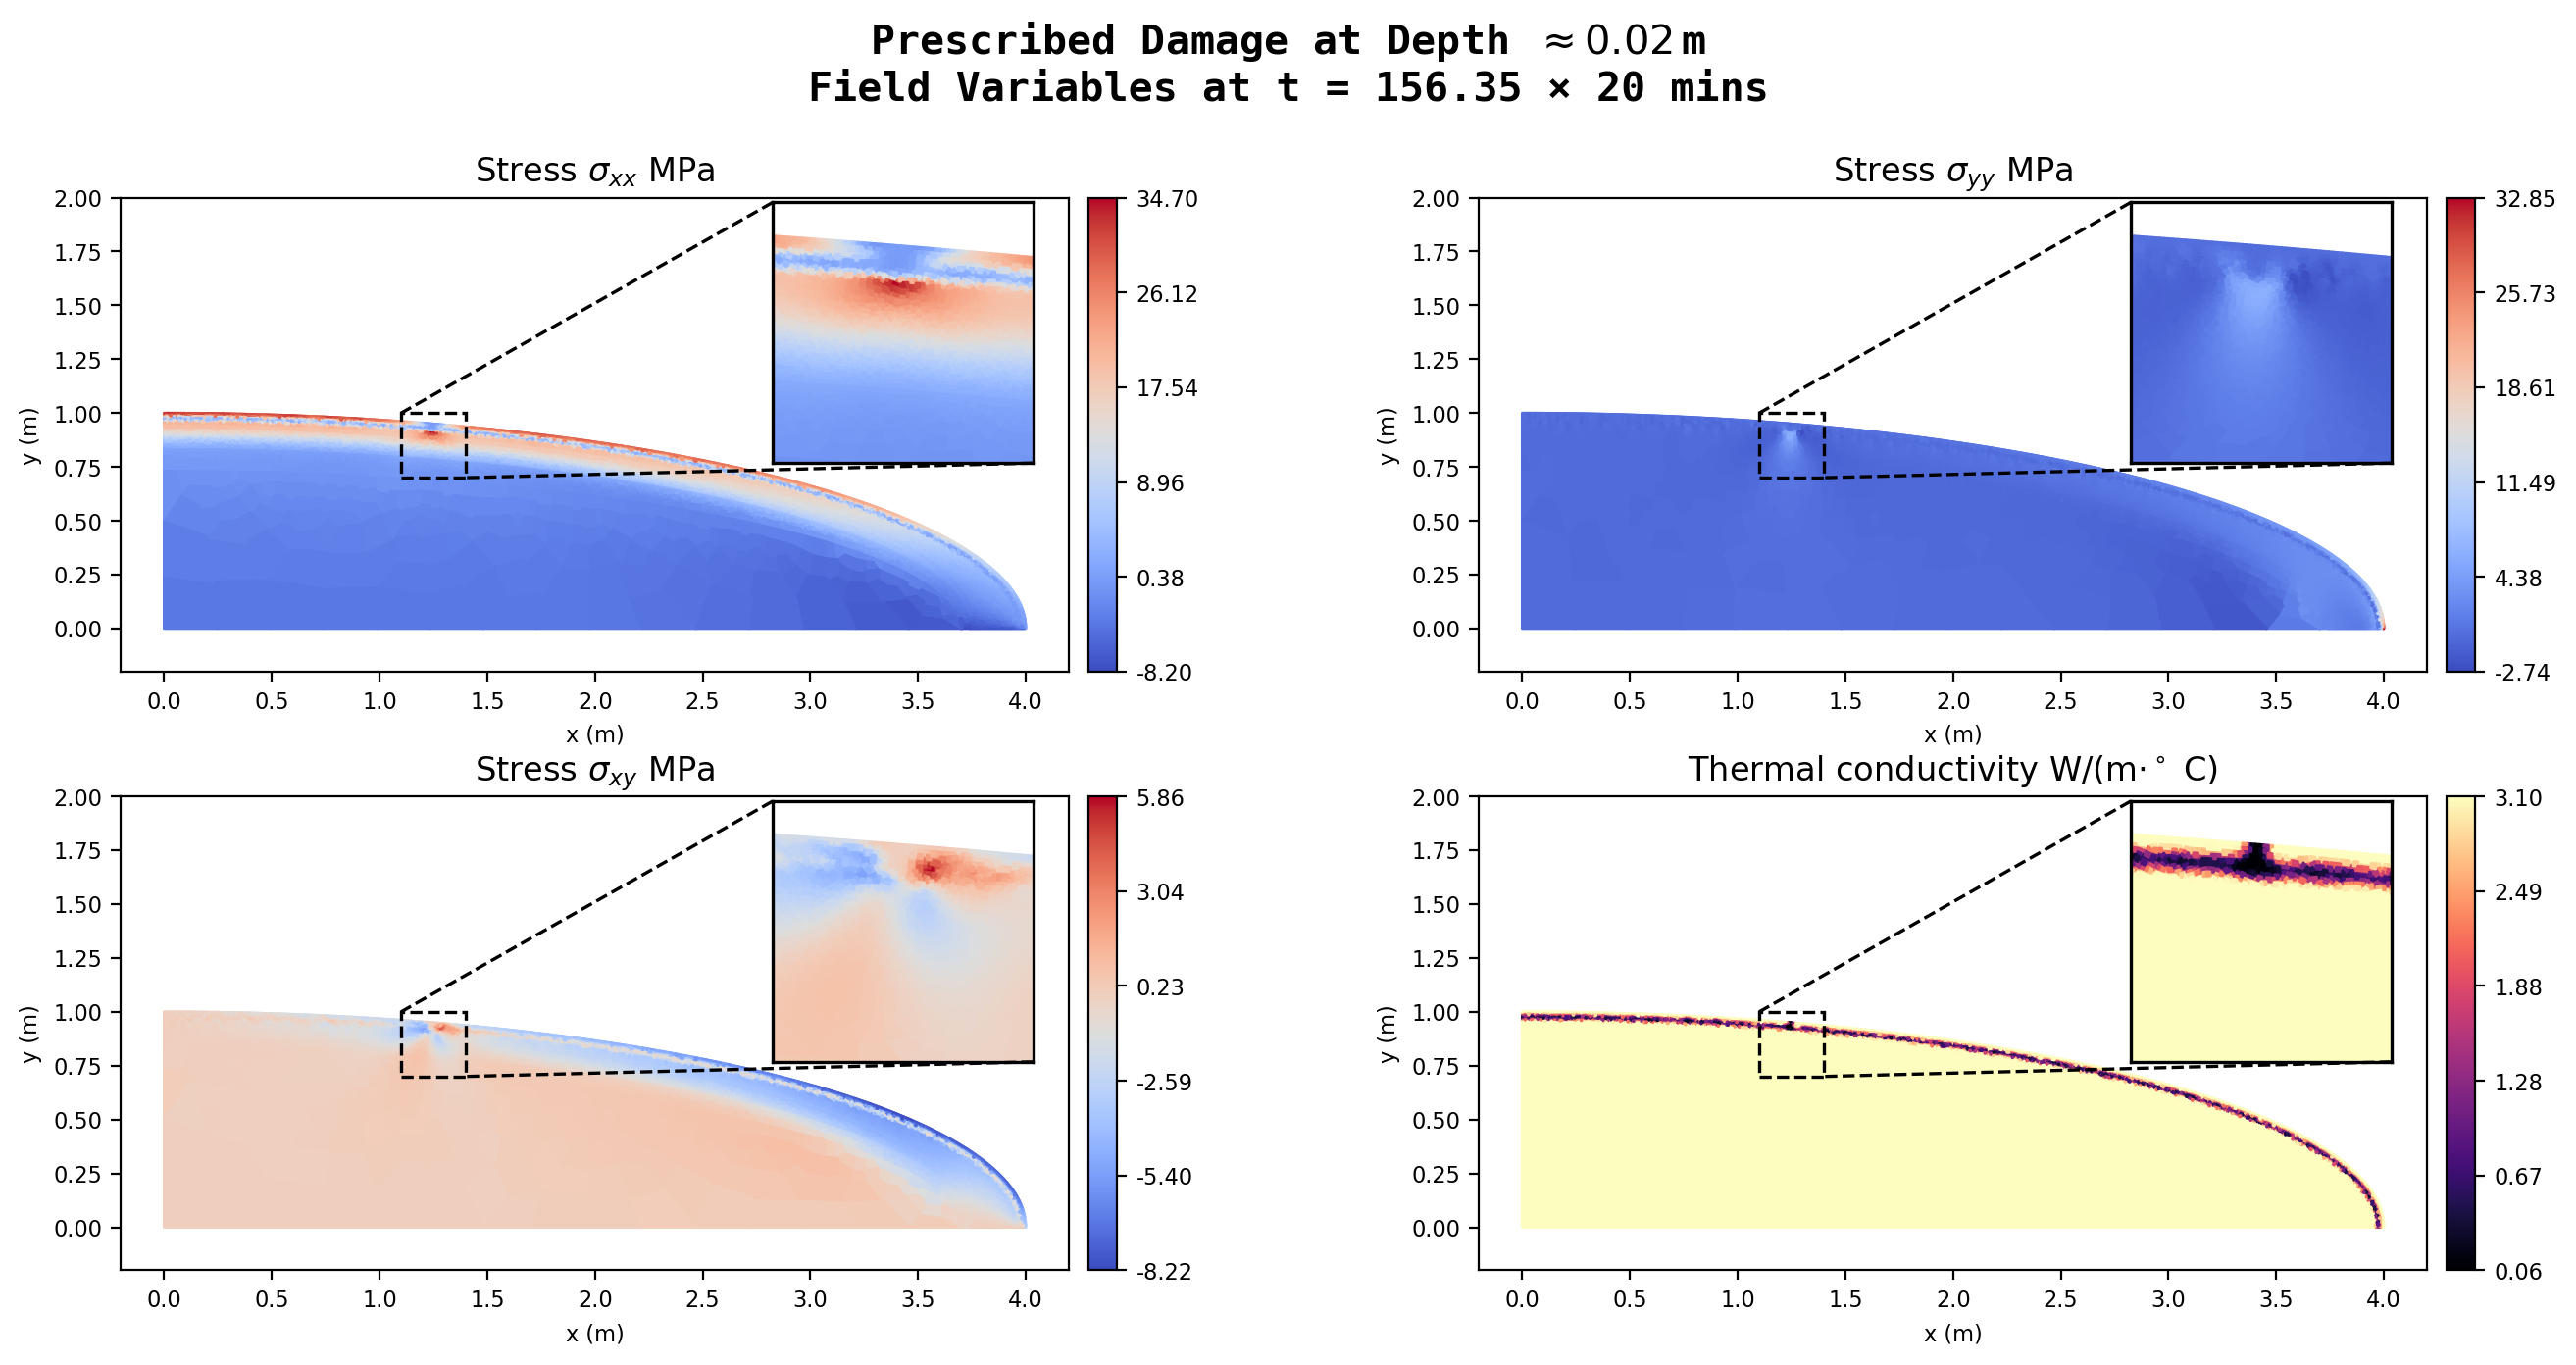

In [14]:
nr, nc = 2, 2  # 子圖數量設定
n_vars = len(elet_vars)

param_idx_list = range(n_vars)  # 要畫哪些變數（你也可以自訂 list）
color_maps=['coolwarm','coolwarm','coolwarm','magma']
e_notations=[False,False,False,False]
zoom_color = ['black','black','black','black']
fig, axes = plt.subplots(nr, nc, figsize=(nc * 7, nr * 3.5), dpi=200)
if nr * nc == 1:
    axes = [axes]
else:
    axes = axes.flatten()

fig.suptitle(
    f"{output_list[1][model_index]}\nField Variables at t = {times[step]:06.2f} × 20 mins",
    fontsize=15, fontweight="bold", fontname="DejaVu Sans Mono"
)


for i, idx in enumerate(param_idx_list):
    #vmin = elet_vars[param_idx_list[i]].min()
    #vmax = elet_vars[param_idx_list[i]].max()
    var = elet_vars[idx][step]
    vmin = var.min()
    vmax = var.max()
    showEltPlot(
        nodes, global_connection, var,
        titlelabel=[elt_var_labels[idx][0], elt_var_labels[idx][1]],
        size=[6, 6], ax = axes[i], p_ext=[0.05, 0.1],
        colormap=color_maps[i], e_notation=e_notations[i],
        assign_bar_range=[vmin, vmax],
        x_unit=r'x (m)', y_unit=r'y (m)',
        font_adjust=1.35
    )

    x1, x2, y1, y2 = 1.1, 1.4, 0.7, 1  # subregion of the original image
    # 小圖（inset）

    axins = axes[i].inset_axes([0.55, 0.44, 0.55, 0.55])  # 位置固定
    showEltPlot(
        nodes, global_connection, var,
        titlelabel=["", ""],
        size=[0, 0], ax=axins, p_ext=[0, 0],  # ✅ 禁止擴張
        colormap=color_maps[i], e_notation=True,
        assign_bar_range=[vmin, vmax],
        x_unit="", y_unit="", font_adjust=0,show_cbar=False,
    )
    axins.set_xlim(x1, x2)
    axins.set_ylim(y1, y2)
    axins.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    for spine in axins.spines.values():
        spine.set_edgecolor(zoom_color[i])   # 顏色
        spine.set_linewidth(1.2)       # 線寬
        spine.set_linestyle("-")       # 線型（可選）

    mark_inset(axes[i], axins, loc1=2, loc2=4, fc="none", ec=zoom_color[i], lw=1.2, ls='--')
####################Add zoom on phase field only########################
    axes[i].set_ylim(-0.2,2)
plt.tight_layout()
plt.subplots_adjust(top=0.85)  # 留空間給 suptitle
plt.show()
fig.savefig(f'figs/fig6b{geo_model_name}_field_zoom_step{times[step]:.2f}.png')
fig.savefig(f'figs/fig6b{geo_model_name}_field_step{times[step]:.2f}.svg')